# F1 Intelligence ML - model analysis

Inspect validation model comparisons, test metrics and feature importance.
Run `python scripts/train_all_models.py` and
`python scripts/evaluate_all_models.py` first.

In [ ]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
while not (project_root / 'config.py').exists() and project_root.parent != project_root:
    project_root = project_root.parent
if not (project_root / 'config.py').exists():
    raise RuntimeError('Run this notebook from the project or notebooks directory')
sys.path.insert(0, str(project_root))

import json
import pandas as pd
import matplotlib.pyplot as plt

import config

report = json.loads((config.REPORTS_DIR / 'evaluation_report.json').read_text(encoding='utf-8'))
for key, value in report['tasks'].items():
    print(key, value.get('algorithm'), value.get('metrics'))

winner/before_qualifying catboost {'log_loss': 0.14454714454577414, 'brier': 0.019184354547642488, 'n_rows': 2010, 'accuracy': 0.13392857142857142, 'top3_hit_rate': 0.13392857142857142, 'n_races': 112}
podium/before_qualifying catboost {'log_loss': 0.33950416047452897, 'brier': 0.08459359771899497, 'n_rows': 2010, 'precision': 0.369047619047619, 'recall': 0.5074404761904762, 'f1': 0.4235119047619048, 'exact_set_accuracy': 0.008928571428571428, 'n_races': 112}
classification/before_qualifying xgboost_ranker {'mae': 3.9751243781094527, 'rmse': 5.571069549054114, 'r2': 0.1487990922105059, 'n_rows': 2010, 'mae_classified': 3.3298167684619657, 'rmse_classified': 4.53764560662298, 'spearman': 0.6515414263933257, 'ndcg_at_10': 0.7483616623978153, 'ranking_accuracy': 0.753118279507003, 'top1_accuracy': 0.125, 'podium_precision_at_3': 0.37142857142857144, 'n_races': 112}
driver_performance/before_qualifying hist_gradient_boosting {'finish_mae': 3.890580435472541, 'finish_rmse': 5.06848609158645

In [2]:
comparison = json.loads((config.TASK_DIRECTORIES['winner'] / 'after_qualifying' / 'comparison.json').read_text(encoding='utf-8'))
rows = []
for candidate in comparison['candidates']:
    rows.append({
        'algorithm': candidate['algorithm'],
        'score': candidate['score'],
        'log_loss': candidate['metrics'].get('log_loss'),
        'accuracy': candidate['metrics'].get('accuracy'),
    })
pd.DataFrame(rows).sort_values('score', ascending=False)

,algorithm,score,log_loss,accuracy
0,catboost,-0.106361,0.106361,0.516667
1,xgboost,-0.108240,0.108240,0.500000
2,lightgbm,-0.111237,0.111237,0.483333
3,catboost,-0.111323,0.111323,0.550000
4,catboost,-0.112387,0.112387,0.516667
5,xgboost,-0.113058,0.113058,0.500000
6,hist_gradient_boosting,-0.114126,0.114126,0.433333
7,xgboost,-0.116206,0.116206,0.516667
8,logistic_regression,-0.122037,0.122037,0.533333
9,lightgbm,-0.124264,0.124264,0.466667


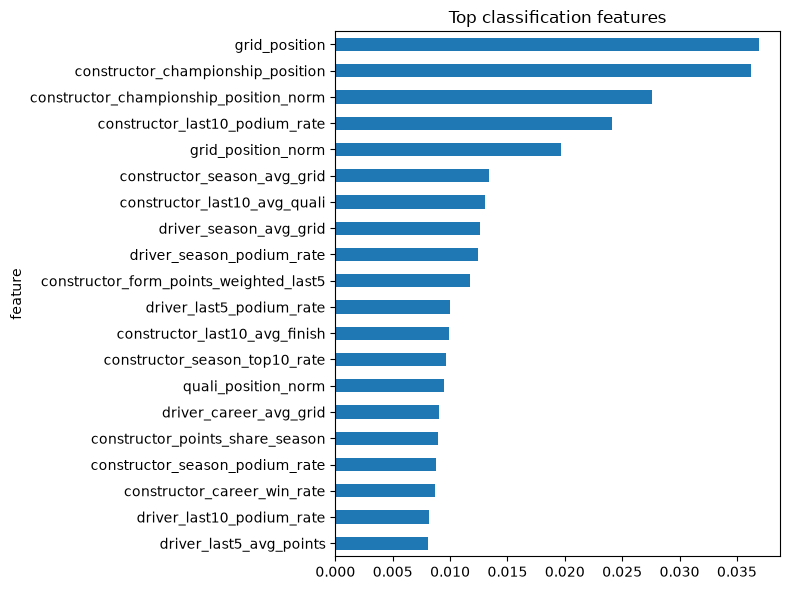

In [3]:
importance = pd.read_csv(config.TASK_DIRECTORIES['classification'] / 'after_qualifying' / 'feature_importance.csv')
if importance.empty:
    print('No feature importance available for this model.')
else:
    importance.head(20).set_index('feature')['importance'].plot(kind='barh', figsize=(8, 6))
    plt.gca().invert_yaxis()
    plt.title('Top classification features')
    plt.tight_layout()
    plt.show()